In [ ]:
import numpy as np
import sympy as smp
from sympy.vector import *
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.integrate import quad_vec

import IPython

# Import IPython display for proper LaTeX formatting
from IPython.display import display, Math, Markdown

import sympy.physics.vector as spv
from sympy.physics.vector.printing import init_vprinting

# Initialize symbols
smp.init_printing()

# Enable dot notation printing for dynamicsymbols
init_vprinting(use_latex="mathjax")

PI = smp.S.Pi
HALF = smp.S.Half
INFINITY = smp.S.Infinity
NEG_INFINITY = smp.S.NegativeInfinity

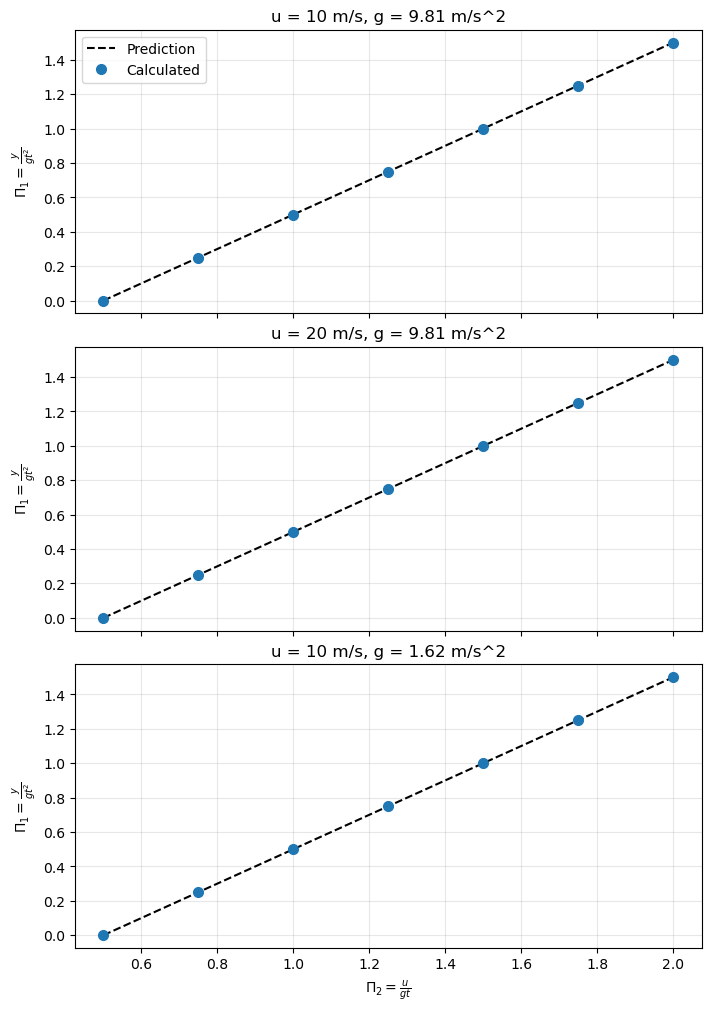

In [11]:
# Compare different initial speeds u and gravitational accelerations g.
cases = [(10.0, 9.81), (20.0, 9.81), (10.0, 1.62)]  # (u in m/s, g in m/s^2)

# Use separate panels with shared scales so the cases can be compared.
fig, axes = plt.subplots(
    3, 1, figsize=(7, 10), sharex=True, sharey=True, constrained_layout=True
)

# Sample evenly in dimensionless Pi_2 to avoid crowding points on the plot.
pi2_line = np.linspace(0.5, 2.0, 200)
pi2_samples = np.linspace(0.5, 2.0, 7)

for ax, (u, g) in zip(axes, cases):
    # Rearrange Pi_2 = u/(g*t) to find the corresponding times; t is nonzero.
    t = u / (g * pi2_samples)
    # Calculate displacement for vertical motion without air resistance.
    y = u * t - 0.5 * g * t**2
    # Form the two dimensionless groups from the physical quantities.
    pi1 = y / (g * t**2)
    pi2 = u / (g * t)
    # Compare the calculated points with the prediction Pi_1 = Pi_2 - 1/2.
    ax.plot(pi2_line, pi2_line - 0.5, "k--", label="Prediction")
    ax.plot(pi2, pi1, "o", markersize=7, label="Calculated")
    ax.set_title(f"u = {u:g} m/s, g = {g:g} m/s^2")
    ax.set_ylabel(r"$\Pi_1 = \frac{y}{gt^2}$")
    ax.grid(True, alpha=0.3)

axes[0].legend()
axes[-1].set_xlabel(r"${\Pi_2 = \frac{u}{gt}}$")
plt.show()